In [21]:
import os
import sys

import joblib
import pandas as pd
import numpy as np

sys.path.insert(0, '../../..') # Load Parent directory to import utils
from utils.helper_functions import normalize_series
from utils.metrics import show_feature_extraction_metrics
from utils.plotting import plot_movement_data
from utils.constants import Configs
from utils.loso_pipeline import run_loso_evaluation
from utils.loso_models.iforest_detector import IForestDetector
from utils.bootstrap_utils import compute_bootstrap_ci_all_levels
from utils.helper_functions import save_loso_results
from utils.helper_functions import append_experiment_record
from utils.loso_pipeline import aggregate_to_trial_level, derive_trial_level_gt, summarize_level
from utils.dtw_radius import load_dtw_matrices

TARGET_MOVEMENT = 'Move'
ALGORITHM_NAME = 'IForest'
MODEL_REPRESENTATION = 'ShapeBased'

EXTRACT_SCORES = True
N_BAYES_TRIALS = 40 # 40 trials is usually the sweet spot for 3 dimensions

In [22]:
# Load the processed data from the csv
cache_path = Configs.ICATER_WRIST_ONLY_FILTERED_DATA_DIR
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)

In [23]:
# Load the known outliers from the csv
outliers_csv = pd.read_csv(Configs.ICATER_OUTLIER_FILES).drop_duplicates(subset=['sub', 'repID', 'movID'])
total_known_outliers = len(outliers_csv)

# Filter the outliers for the target movement
outliers_csv = outliers_csv[outliers_csv['movLabel'] == TARGET_MOVEMENT].reset_index(drop=True)
total_target_outliers = len(outliers_csv)

print(f"Total known outliers: {total_known_outliers}")
print(f"Total target outliers: {total_target_outliers}")
outliers_csv.head()

Total known outliers: 18
Total target outliers: 5


,sub,repID,movID,movLabel
0,2,2,9,Move
1,4,1,9,Move
2,7,1,9,Move
3,11,1,9,Move
4,12,1,9,Move


In [24]:
df = df.sort_values(by=['sub', 'repID', 'movID', 'step']).reset_index(drop=True)
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()

group_array = ['x', 'y', 'z']
sample_size = None

X_movement = normalize_series(
        df_input=df,
        movLabel_filter=TARGET_MOVEMENT,
        useScaler=False,
        group_array=group_array,
        sample_size=sample_size
)  # shape (n_samples, T, n_features)

Processing time series: 100%|██████████| 95/95 [00:00<00:00, 2693.95it/s]

Shape of first series: (72, 3)
Shape of formatted series: (95, 196, 3)


In [25]:
# =========================================================================
# Base vars for future calculations 
# =========================================================================

results_temp_base = df_filtered[['sub', 'repID', 'movID']].drop_duplicates().reset_index(drop=True)

total_samples = len(results_temp_base)                                  
total_trials  = len(df_filtered[['sub', 'repID']].drop_duplicates())
known_outlier_rate = (total_target_outliers / total_samples) if total_samples > 0 else 0.0
percentagem_conhecida = known_outlier_rate * 100

if total_samples != X_movement.shape[0]:
    raise ValueError(f"⚠️ CRITICAL ERROR: Metadata ({total_samples}) does not match Matrix ({X_movement.shape[0]})!")

print(f"✅ Perfect Synchronization! Rows in Matrix: {X_movement.shape[0]} | Rows in Metadata: {total_samples}")
print(f"Total samples in Matrix: {total_samples}")
print(f"Total unique repetitions analyzed ({TARGET_MOVEMENT}): {total_trials}")
print(f"Minimum confirmed outlier rate from CSV (Sub + RepID + movID): {percentagem_conhecida:.2f}%")

✅ Perfect Synchronization! Rows in Matrix: 95 | Rows in Metadata: 95
Total samples in Matrix: 95
Total unique repetitions analyzed (Move): 95
Minimum confirmed outlier rate from CSV (Sub + RepID + movID): 5.26%


In [26]:
if total_target_outliers == 0:
    raise RuntimeError(
        f"'{TARGET_MOVEMENT}' Does not have any known positive cases at the movement level. "
    )

## Local Outlier Factor (LOC)

### Grid Search

In [27]:
FIXED_SEED = 42

contamination_range = Configs.CONTAMINATION_GRID
# Cannot use itertools when I'm using Bayesian optimization
param_space = {
    'n_estimators': ('int', 50, 500),
    'max_samples': ('categorical', ['auto', 0.3, 0.5, 0.7, 0.9]),
    'contamination': ('categorical', Configs.CONTAMINATION_GRID),
    'random_state': FIXED_SEED
}

matrices = load_dtw_matrices(TARGET_MOVEMENT, Configs.DTW_RADIUS_Seconds, Configs.wrist_only_constrained_dtw_distance_matrix)

loso_results = run_loso_evaluation(
    detector_class=IForestDetector, 
    param_grid=param_space,
    data_matrix=matrices[0.5], # TODO placeholder, replaced per fold TODO
    metadata_df=results_temp_base,
    known_outliers_df=outliers_csv,
    search_type='bayesian',
    n_bayes_trials=N_BAYES_TRIALS,
    metric_type='precomputed', # the metric type is a lie
    compute_trial_level=False,
    extract_scores=EXTRACT_SCORES,
    print_results=False,
    dtw_matrices=matrices
)

print("\nSearch Results:")
print("Teste", f"MCC={loso_results['MCC']:.3f}", f"Rej={loso_results['Rejection_Rate']:.1f}%",
          f"AUROC={loso_results['AUROC']:.3f}")

LOSO Cross-Validation with 19 subjects (5 known positive movements)...
Evaluating Subject: 1 | Evaluating Subject: 2 | Evaluating Subject: 3 | Evaluating Subject: 4 | Evaluating Subject: 5 | Evaluating Subject: 6 | Evaluating Subject: 7 | Evaluating Subject: 8 | Evaluating Subject: 9 | Evaluating Subject: 10 | Evaluating Subject: 11 | Evaluating Subject: 12 | Evaluating Subject: 13 | Evaluating Subject: 14 | Evaluating Subject: 15 | Evaluating Subject: 16 | Evaluating Subject: 17 | Evaluating Subject: 18 | Evaluating Subject: 19 | 
Search Results:
Teste MCC=0.497 Rej=3.2% AUROC=0.744


In [28]:
best_params = loso_results['Best_Params']
n_estimators = best_params['n_estimators']
contamination = best_params['contamination']
max_samples = best_params['max_samples']

selected_radius = loso_results['Most_Frequent_DTW_Radius']
selected_dtw_matrix = matrices[selected_radius]      # `matrices` is the dict loaded earlier

## Report Seed Variance

In [29]:
# Extract the exact hyperparameter dictionary used for each specific subject in the original run
fold_params = {
    fold['subject_out']: fold['params'].copy()
    for fold in loso_results['Fold_History']
}

In [30]:
# --- Variance Evaluation for Stochastic Model ---
test_seeds = [10, 42, 123, 999, 2026]
f2_scores_seeds = []
precision_scores = []
recall_scores = []
auprc_scores = []
mcc_scores = []
all_seed_results = []

for seed in test_seeds:
    # Single configuration grid with changing seed
    param_space_seed = {
        'n_estimators': ('int', 50, 500),
        'max_samples': ('categorical', ['auto', 0.3, 0.5, 0.7, 0.9]),
        'contamination': ('categorical', Configs.CONTAMINATION_GRID),
        'random_state': seed
    }
    
    # Run LOSO purely for this specific configuration
    seed_results = run_loso_evaluation(
        detector_class=IForestDetector, 
        param_grid=param_space_seed,
        data_matrix=matrices[0.5], # TODO should I put here selected data matrices and remove dtw_matrices from this call?
        metadata_df=results_temp_base,
        known_outliers_df=outliers_csv,
        search_type='bayesian',
        n_bayes_trials=N_BAYES_TRIALS,
        metric_type='precomputed', 
        fixed_fold_params=fold_params,
        override_random_state=seed,
        compute_trial_level=False,
        extract_scores=EXTRACT_SCORES,
        print_results=False,
        dtw_matrices=matrices
    )

    all_seed_results.append(seed_results) 
    mcc_scores.append(seed_results['Movement']['MCC'])
    f2_scores_seeds.append(seed_results['Movement']['F2-Score'])
    precision_scores.append(seed_results['Movement']['Precision'])
    recall_scores.append(seed_results['Movement']['Recall'])

    if EXTRACT_SCORES:
        auprc_scores.append(seed_results['Movement']['AUPRC'])

print("\n\n--- IForest Stability Results - 5 seeds (mean ± std) ---")
print(f"F2-Score:  {np.mean(f2_scores_seeds):.2f}% ± {np.std(f2_scores_seeds):.3f}%")
print(f"Precision: {np.mean(precision_scores):.2f}% ± {np.std(precision_scores):.3f}%")
print(f"Recall:    {np.mean(recall_scores):.2f}% ± {np.std(recall_scores):.3f}%")
print(f"MCC:       {np.mean(mcc_scores):.2f}% ± {np.std(mcc_scores):.3f}%")
print(f"AUPRC:     {np.mean(auprc_scores):.2f}% ± {np.std(auprc_scores):.3f}%")
print("-------------------------------------------")

LOSO Cross-Validation with 19 subjects (5 known positive movements)...
Evaluating Subject: 1 | Evaluating Subject: 2 | Evaluating Subject: 3 | Evaluating Subject: 4 | Evaluating Subject: 5 | Evaluating Subject: 6 | Evaluating Subject: 7 | Evaluating Subject: 8 | Evaluating Subject: 9 | Evaluating Subject: 10 | Evaluating Subject: 11 | Evaluating Subject: 12 | Evaluating Subject: 13 | Evaluating Subject: 14 | Evaluating Subject: 15 | Evaluating Subject: 16 | Evaluating Subject: 17 | Evaluating Subject: 18 | Evaluating Subject: 19 | LOSO Cross-Validation with 19 subjects (5 known positive movements)...
Evaluating Subject: 1 | Evaluating Subject: 2 | Evaluating Subject: 3 | Evaluating Subject: 4 | Evaluating Subject: 5 | Evaluating Subject: 6 | Evaluating Subject: 7 | Evaluating Subject: 8 | Evaluating Subject: 9 | Evaluating Subject: 10 | Evaluating Subject: 11 | Evaluating Subject: 12 | Evaluating Subject: 13 | Evaluating Subject: 14 | Evaluating Subject: 15 | Evaluating Subject: 16 | E

In [31]:
oof_movement_per_seed = [sr['OOF_Movement'] for sr in all_seed_results]

reference_keys = oof_movement_per_seed[0][['sub', 'repID', 'movID', 'true_is_outlier']].reset_index(drop=True)
for oof in oof_movement_per_seed[1:]:
    keys = oof[['sub', 'repID', 'movID', 'true_is_outlier']].reset_index(drop=True)
    assert reference_keys.equals(keys), "As linhas de OOF_Movement divergem entre seeds."

stacked_preds = np.stack([oof['pred_is_outlier'].values for oof in oof_movement_per_seed], axis=0)
consensus_pred = (stacked_preds.mean(axis=0) >= 0.5).astype(int)

if all(oof['anomaly_score'].notna().all() for oof in oof_movement_per_seed):
    stacked_scores = np.stack([oof['anomaly_score'].values for oof in oof_movement_per_seed], axis=0)
    consensus_score = stacked_scores.mean(axis=0)
else:
    consensus_score = np.full(len(reference_keys), np.nan)

oof_movement_consensus = reference_keys.copy()
oof_movement_consensus['pred_is_outlier'] = consensus_pred
oof_movement_consensus['anomaly_score'] = consensus_score

trial_outliers_gt = derive_trial_level_gt(outliers_csv)
oof_trial_consensus = aggregate_to_trial_level(oof_movement_consensus, trial_outliers_gt, score_col='anomaly_score')

movement_summary_consensus = summarize_level(oof_movement_consensus, 'movement', len(outliers_csv))
trial_summary_consensus = summarize_level(oof_trial_consensus, 'trial', len(trial_outliers_gt))

In [32]:
loso_results_consensus = dict(loso_results)
loso_results_consensus['Movement'] = movement_summary_consensus
# loso_results_consensus['Trial'] = trial_summary_consensus
loso_results_consensus['OOF_Movement'] = oof_movement_consensus
# loso_results_consensus['OOF_Trial'] = oof_trial_consensus
loso_results_consensus['Blind_Y_True'] = oof_movement_consensus['true_is_outlier'].values
loso_results_consensus['Blind_Y_Pred'] = oof_movement_consensus['pred_is_outlier'].values

print("--- IForest (Feature-Based, Seed-Robust Consensus) -- nível de MOVIMENTO ---")
for k in ['Precision', 'Recall', 'F1-Score', 'F2-Score', 'MCC', 'AUPRC', 'AUROC', 'Rejection_Rate']:
    v = movement_summary_consensus.get(k, np.nan)
    print(f"  {k}: {v:.4f}" if isinstance(v, float) and not np.isnan(v) else f"  {k}: {v}")

--- IForest (Feature-Based, Seed-Robust Consensus) -- nível de MOVIMENTO ---
  Precision: 0.6667
  Recall: 0.4000
  F1-Score: 0.5000
  F2-Score: 0.4348
  MCC: 0.4966
  AUPRC: 0.6241
  AUROC: 0.6889
  Rejection_Rate: 3.1579


## Bootstrap CI interval 95%

In [33]:
ci_results_consensus = compute_bootstrap_ci_all_levels(loso_results_consensus, compute_scores=EXTRACT_SCORES, seed=42)

In [34]:
save_loso_results(
    model_name=ALGORITHM_NAME,
    representation=MODEL_REPRESENTATION,
    target_movement=TARGET_MOVEMENT,
    loso_results=loso_results_consensus,
)

append_experiment_record(
    summary_path=Configs.WRIST_ONLY_CSV_SHAPE_BASED_SUMMARY_FILE,
    phase=TARGET_MOVEMENT,
    representation=MODEL_REPRESENTATION,
    algorithm=ALGORITHM_NAME,
    total_samples=total_samples,
    loso_results=loso_results_consensus,
    bootstrap_results=ci_results_consensus,
)


✅ Experiment Summary for IForest - ShapeBased - Move - 95 Movements (MOVEMENT-level):
Unique Outliers Detected: 3
Rejection Rate: 3.16%
Known Positives in Ground Truth: 5
------------------------------
Total True Positives (Global):  2
Total False Positives (Global): 1
Total False Negatives (Global): 3
Total True Negatives (Global):  89
------------------------------
Blind Precision: 66.67 [0.00–100.00]
Blind Recall:    40.00 [0.00–100.00]
Blind F1-Score:  50.00
Blind F2-Score:  43.48 [0.00–86.37]
Blind MCC:       0.50 [-0.03–0.86]
Blind AUPRC:  62.41 [3.53–100.00]
Blind AUROC:   68.89

Total Tuning Time (19 Subjects): 455.4624s
Total Inference Time (19 Subjects): 2.1917s

Overall Best Parameters (Most frequent across folds):
   {'contamination': 0.03, 'max_samples': 'auto', 'n_estimators': 65, 'random_state': 42}
Occurrences: 13


### Train Model
Reconstruct the exact trial order used by LOSO (without modifying `loso_pipeline.py`).

`_aggregate_test_predictions` iterates over subjects in their order of first appearance in `metadata_df` and groups each subject by `(sub, repID)` in ascending `repID` order.

We reproduce this logic here to assign `consensus_outlier_keys` to the correct trials.

In [35]:
consensus_outlier_keys = set(
    zip(oof_trial_consensus[oof_trial_consensus['pred_is_outlier'] == 1]['sub'],
        oof_trial_consensus[oof_trial_consensus['pred_is_outlier'] == 1]['repID'])
)
print(f"✅ {len(consensus_outlier_keys)} trials marked as outlier by consensus.")

✅ 3 trials marked as outlier by consensus.


In [36]:
# Reconstruir metadados ao nível do segmento, para os plots (mesmo padrão do notebook DBSCAN DTW)
grouped_keys = df_filtered.groupby(['sub', 'repID', 'movID', 'movLabel'], sort=False).groups.keys()
metadata_df = pd.DataFrame(list(grouped_keys), columns=['sub', 'repID', 'movID', 'movLabel'])

# Marcar outlier ao nível do segmento com base no consenso (trial-level -> segment-level)
metadata_df['anomaly'] = metadata_df.apply(
    lambda row: -1 if (row['sub'], row['repID']) in consensus_outlier_keys else 1,
    axis=1
)

outlier_indices = np.where(metadata_df['anomaly'].values == -1)[0]

n_outliers = len(outlier_indices)
total_trials_consensus = len(oof_trial_consensus)
correct_trash_pct = (n_outliers / total_trials_consensus) * 100 if total_trials_consensus > 0 else 0.0
n_unique_outliers = n_outliers

print(f"Unique Outlier Trials Detected (Consensus): {n_unique_outliers}")
print(f"Rejection Rate (Consensus): {correct_trash_pct:.2f}%")

X_movement_clean = np.delete(X_movement, outlier_indices, axis=0)
X_movement_outliers = X_movement[outlier_indices]

Unique Outlier Trials Detected (Consensus): 3
Rejection Rate (Consensus): 3.16%


In [37]:
real_outliers_info = metadata_df.iloc[outlier_indices][["sub", "repID", "movID", "movLabel"]]
identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

print("Quem são os outliers reais?")
print(real_outliers_info)

Quem são os outliers reais?
    sub  repID  movID movLabel
6     2      2      9     Move
15    4      1      9     Move
79   16      5      9     Move


In [38]:
identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

matched_outliers = pd.merge(identified_unique, outliers_csv, on=['sub', 'repID'], how='inner')

missing_outliers = pd.merge(outliers_csv, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']

metrics = show_feature_extraction_metrics(
    metadata_df,
    outliers_csv,
    identified_unique,
    matched_outliers,
    missing_outliers
)

--- Confusion Matrix (Based on sub+repID) ---
True Positives (Identified and in CSV) : 2
False Positives (Identified, not in CSV): 1
False Negatives (In CSV, not identified): 3
True Negatives (Normal, stayed normal): 89
--------------------------------------------------
Missing outliers (In CSV, not identified):
   sub  repID
2    7      1
3   11      1
4   12      1

Precision (False Positives): 2/3 (66.67%)
Recall (True Positive Rate): 2/5 (40.00%)
F1-Score: 50.00%
F2-Score: 43.48%


### Plot Things

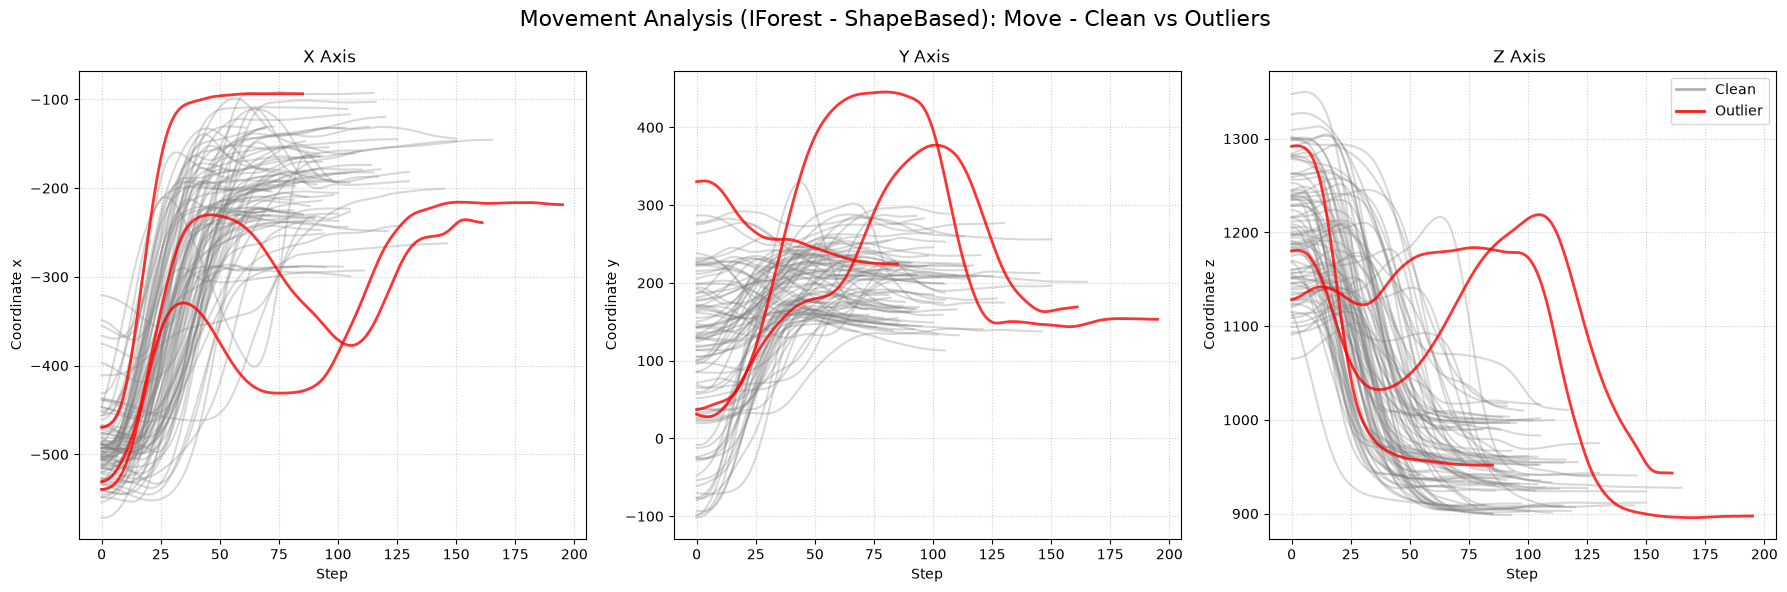

In [39]:
plot_movement_data(
    clean_data=X_movement_clean,
    outlier_data=X_movement_outliers,
    target_movement=TARGET_MOVEMENT,
    algorithm_name=ALGORITHM_NAME,
    save_fig=Configs.SAVE_PLOTS,
    save_path=Configs.DESKTOP_PATH,
    model_representation=MODEL_REPRESENTATION,
)